In [1]:
import numpy as np
from invlap import invlap
import matplotlib.pyplot as plt
import sympy as symp
from scipy.optimize import minimize
import scipy.linalg as sla
import time

In [2]:
def ADE_sol(ts, xs, v, D):
    """
    Solves the advection-diffusion equation
    ts = Array. Times after release
    xs = Array. Distance from the point of release
    v = Float. Advection velocity
    D = Float. Diffusion coefficient
    """
    def sol_lap_space(s, x):
        Delta =  np.sqrt(v**2+4*D*s)/(2*D)
        alpha_plus = (v + np.sqrt(v**2+4*D*s))/(2*D)
        alpha_minus = (v - np.sqrt(v**2+4*D*s))/(2*D)
        # U = (alpha_minus*np.exp(alpha_minus+alpha_plus*x)-alpha_plus*np.exp(alpha_plus+alpha_minus*x))/(s*(alpha_minus*np.exp(alpha_minus)-alpha_plus*np.exp(alpha_plus))) #This doesn't work due to very large exponentials, we subtract Delta from all exponentials to remove this issue
        U = (alpha_minus*np.exp(alpha_minus+alpha_plus*x-Delta)-alpha_plus*np.exp(alpha_plus+alpha_minus*x-Delta))/(s*(alpha_minus*np.exp(alpha_minus-Delta)-alpha_plus*np.exp(alpha_plus-Delta)))
        return U
    u = np.array([invlap(sol_lap_space, ts, [x]) for x in xs])
    return u

In [3]:
Nt = 200
Nx = 200
ts = np.linspace(0,1,Nt+1)
xs = np.linspace(0,1,Nx+1)
v = 0.213*805/86
D = 0.037*805/86**2
u = np.zeros((Nt+1,Nx+1))
u[1:] = ADE_sol(ts[1:], xs, v, D).T
u = np.nan_to_num(u,nan = 0.0)

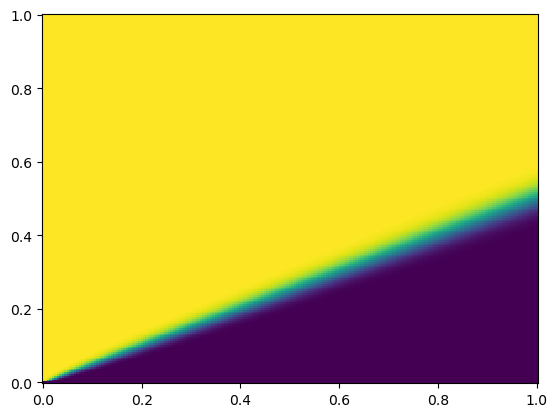

In [4]:
import matplotlib.pyplot as plt
ax = plt.gca()
plt.pcolormesh(xs,ts,u)

In [5]:
u_pred = np.load('PINN_problem_2_fwd_output.npy')
u_preDinv = np.load('PINN_problem_2_inv_output.npy')

In [6]:
berkowitz_data = np.genfromtxt('homo1.txt', delimiter=',', skip_header=1)
data_t = berkowitz_data[:,0]/berkowitz_data[-1,0]
data_vals = berkowitz_data[:,1]

(0.35, 0.7)

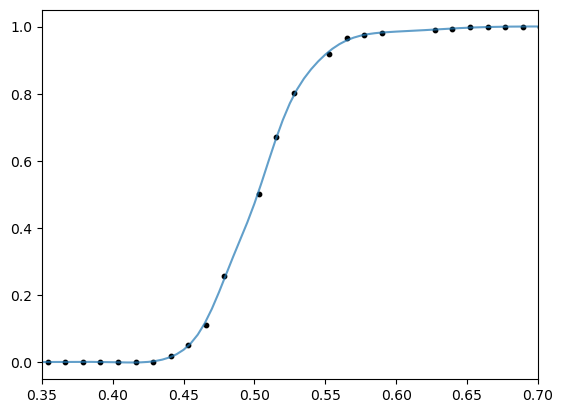

In [7]:
plt.scatter(data_t,data_vals, c='k', s = 10.0)
plt.plot(ts,u_preDinv[:,-1],alpha = 0.7)
plt.xlim(0.35,0.7)

In [8]:
x, t = symp.symbols('x t', real=True)
xi, ti = symp.symbols('x_i t_i', real=True)  # center of basis φ
hx, ht = symp.symbols('h_x h_t', positive=True, real=True)
x0, t0 = symp.symbols('x_0 t_0', real=True)

phi = (1/symp.sqrt(2*symp.pi)/hx) * symp.exp(-(x - xi)**2/(2*hx**2)) \
    * (1/symp.sqrt(2*symp.pi)/ht) * symp.exp(-(t - ti)**2/(2*ht**2))

phi_t = symp.diff(phi, t)
phi_x = symp.diff(phi, x)
phi_xx = symp.diff(phi, x, 2)



phi_fun = symp.lambdify((x,t,xi,ti,hx,ht), phi, "numpy")
phi_t_fun = symp.lambdify((x,t,xi,ti,hx,ht), phi_t, "numpy")
phi_x_fun = symp.lambdify((x,t,xi,ti,hx,ht), phi_x, "numpy")
phi_xx_fun = symp.lambdify((x,t,xi,ti,hx,ht), phi_xx, "numpy")

zero = symp.lambdify((x,t,xi,ti,hx,ht), 0.0, "numpy")

phi_fun_minus = symp.lambdify((x,t,xi,ti,hx,ht), -phi, "numpy")
phi_t_fun_minus = symp.lambdify((x,t,xi,ti,hx,ht), -phi_t, "numpy")
phi_x_fun_minus = symp.lambdify((x,t,xi,ti,hx,ht), -phi_x, "numpy")
phi_xx_fun_minus = symp.lambdify((x,t,xi,ti,hx,ht), -phi_xx, "numpy")

R_IC_dirich = phi.subs(t, t0)
R_BC_dirich = phi.subs(x, x0)
R_BC_neumann = phi_x.subs(x, x0)

R_IC_dirich_fun = symp.lambdify((x,t,xi,ti,hx,ht,t0), R_IC_dirich, "numpy")
R_BC_dirich_fun = symp.lambdify((x,t,xi,ti,hx,ht,x0), R_BC_dirich, "numpy")
R_BC_neumann_fun =  symp.lambdify((x,t,xi,ti,hx,ht,x0), R_BC_neumann, "numpy")

In [9]:
def compute_matrices_for_inverse(x_star,Nx,Nt,h_fac,extra_p,col_fac,
                                 data_x,data_t,
                                 PDE_funcs,R_funcs_rest,
                                 funcs_b,xt_stars):
    print(x_star,Nx,Nt,h_fac,extra_p,col_fac)
    ## RBF centers
    deltax = 1/Nx
    deltat = 1/Nt
    hx = 1/Nx * h_fac
    ht = 1/Nt * h_fac
    xis = np.arange(-extra_p,Nx+extra_p+1)*deltax
    tis = np.arange(-extra_p,Nt+extra_p+1)*deltat
    Xis, Tis = np.meshgrid(xis, tis)
    Xis = Xis.flatten()
    Tis = Tis.flatten()
    
    # Colocation nodes
    x_evals = np.linspace(0,1,int(col_fac*Nx)+1)
    t_evals = np.linspace(0,1,int(col_fac*Nt)+1)
    ## Computing A
    wx = np.trapezoid(np.eye(len(x_evals)), x=x_evals, axis=1)  # weights on x
    wt = np.trapezoid(np.eye(len(t_evals)), x=t_evals, axis=1)  # weights on t
    
    # PDE_funcs = [phi_t_fun,phi_x_fun,phi_xx_fun]
    A_PDE = np.zeros((len(PDE_funcs),len(PDE_funcs),len(Xis),len(Xis)))
    for i in range(len(PDE_funcs)):
        R_PDE_eval_i = PDE_funcs[i](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
        R_PDE_eval_i = R_PDE_eval_i.reshape(t_evals.size * x_evals.size, len(Xis))
        for j in range(len(PDE_funcs)):
            R_PDE_eval_j = PDE_funcs[j](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
            R_PDE_eval_j = R_PDE_eval_j.reshape(t_evals.size * x_evals.size, len(Xis))
            # Full Kronecker weights on the flattened grid
            A_PDE[i,j] = (R_PDE_eval_i * (np.kron(wx, wt))[:, None]).T @ R_PDE_eval_j

    A_rest = np.zeros((len(Xis),len(Xis)))

    for R_fun in R_funcs_rest:
        R_eval = R_fun(x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
        if R_eval.shape[0]==1:
            A_rest += (R_eval.reshape(x_evals.size, len(Xis)) * (wx)[:, None]).T @ R_eval.reshape(x_evals.size, len(Xis))
        if R_eval.shape[1]==1:
            A_rest += (R_eval.reshape(t_evals.size, len(Xis)) * (wt)[:, None]).T @ R_eval.reshape(t_evals.size, len(Xis))

    phi_data_eval = phi_fun(data_x[:,None],data_t[:,None],Xis,Tis,hx,ht)
    
    b_PDE = np.zeros((len(PDE_funcs),len(Xis)))
    b_rest = np.zeros(len(Xis))
    
    for i in range(len(funcs_b)):
        if xt_stars[i]!=None:
            if i == 0:
                for j in range(len(PDE_funcs)):
                    if xt_stars[i][0]==None:
                        b_PDE[j] = funcs_b[i]*np.sum(PDE_funcs[j](x_evals[:,None],xt_stars[i][1],Xis,Tis,hx,ht)*(wx)[:, None],axis = 0)
                    elif xt_stars[i][1]==None:
                        b_PDE[j] = funcs_b[i]*np.sum(PDE_funcs[j](xt_stars[i][0],t_evals[:,None],Xis,Tis,hx,ht)*(wt)[:, None],axis = 0)
                    else:
                        b_PDE[j] += funcs_b[i]*PDE_funcs[j](xt_stars[i][0],xt_stars[i][1],Xis,Tis,hx,ht)
            if i>0:
                b_rest += funcs_b[i]*R_funcs_rest[i-1](xt_stars[i],xt_stars[i],Xis,Tis,hx,ht)
        else:
            if callable(funcs_b[i]):
                rhs = funcs_b[i](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
            if type(funcs_b[i]) == float or type(funcs_b[i]) == int:
                rhs = np.array([funcs_b[i]])[None,None,:]
            if i ==0:
                for j in range(len(PDE_funcs)):
                    R_PDE_eval_j = PDE_funcs[j](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht)
                    R_PDE_eval_j_mul = (rhs*R_PDE_eval_j).reshape(t_evals.size * x_evals.size, len(Xis))
                    b_PDE[j] = np.sum(R_PDE_eval_j_mul*(np.kron(wx, wt))[:, None],axis = 0)
            if i>0:
                b_rest += np.sum(wx[None,:,None]* wt[:,None,None]*rhs*R_funcs_rest[i-1](x_evals[None,:,None],t_evals[:,None,None],Xis,Tis,hx,ht),axis = (0,1))
    
    return A_PDE,phi_data_eval,A_rest,b_PDE,b_rest

In [10]:
def no_grad_optimize_inverse(par, A_par_dep,A_par_indep,b_par_dep,b_par_indep,phi_data_eval,data_vals,epsilon = 10**-6):
    params = np.concatenate(([1.0],par))
    A = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + A_par_indep + np.eye(len(A_par_indep))*epsilon
    b = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + b_par_indep
    u = np.linalg.solve(A,b)
    
    u_loc = np.sum(u * phi_data_eval, axis=-1)

    e = u_loc - data_vals
    R = e@e
    
    return R

def grad_optimize_inverse(par, A_par_dep,A_par_indep,b_par_dep,b_par_indep,phi_data_eval,data_vals,epsilon = 10**-6):
    params = np.concatenate(([1.0],par))
    A = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + A_par_indep + np.eye(len(A_par_indep))*epsilon
    b = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + b_par_indep
    L = sla.cholesky(A, lower=True)
    u_aux = sla.solve_triangular(L, b, lower=True)
    u = sla.solve_triangular(L.T, u_aux, lower=False)
    
    u_loc = np.sum(u * phi_data_eval, axis=-1)

    e = u_loc - data_vals
    R = e@e

    dA_dp = np.array([(np.tensordot(A_par_dep[i], params, axes=(0, 0)) +
              np.tensordot(A_par_dep[:, i], params, axes=(0, 0))) for i in range(1,len(params))])
    
    db_dp = np.array([(np.tensordot(b_par_dep[i], params, axes=(0, 0)) +
              np.tensordot(b_par_dep[:, i], params, axes=(0, 0))) for i in range(1,len(params))])

    du_dp_aux = [sla.solve_triangular(L, db_dp[i]-dA_dp[i]@u, lower=True) for i in range(len(params)-1)]
    du_dp = np.array([sla.solve_triangular(L.T, du_dp_aux[i], lower=False) for i in range(len(params)-1)])

    de_dp = np.sum(du_dp[:,None,:] * phi_data_eval[None,:,:], axis=-1)

    dR_dp = 2*np.sum(e[None,:]*de_dp,axis=-1)
    return R, dR_dp

def grad_hess_optimize_inverse(par, A_par_dep,A_par_indep,b_par_dep,b_par_indep,phi_data_eval,data_vals,epsilon = 10**-6):
    params = np.concatenate(([1.0],par))
    A = np.tensordot(np.tensordot(A_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + A_par_indep + np.eye(len(A_par_indep))*epsilon
    b = np.tensordot(np.tensordot(b_par_dep, params, axes=(0, 0)), params, axes=(0, 0)) + b_par_indep
    L = sla.cholesky(A, lower=True)
    u_aux = sla.solve_triangular(L, b, lower=True)
    u = sla.solve_triangular(L.T, u_aux, lower=False)
    
    u_loc = np.sum(u * phi_data_eval, axis=-1)

    e = u_loc - data_vals
    R = e@e

    dA_dp = np.array([(np.tensordot(A_par_dep[i], params, axes=(0, 0)) +
              np.tensordot(A_par_dep[:, i], params, axes=(0, 0))) for i in range(1,len(params))])
    
    db_dp = np.array([(np.tensordot(b_par_dep[i], params, axes=(0, 0)) +
              np.tensordot(b_par_dep[:, i], params, axes=(0, 0))) for i in range(1,len(params))])

    du_dp_aux = [sla.solve_triangular(L, db_dp[i]-dA_dp[i]@u, lower=True) for i in range(len(params)-1)]
    du_dp = np.array([sla.solve_triangular(L.T, du_dp_aux[i], lower=False) for i in range(len(params)-1)])

    de_dp = np.sum(du_dp[:,None,:] * phi_data_eval[None,:,:], axis=-1)

    dR_dp = 2*np.sum(e[None,:]*de_dp,axis=-1)

    d2A_dp2 = np.array([[A_par_dep[i,j]+A_par_dep[j,i] for j in range(1,len(params))] for i in range(1,len(params))])
    d2b_dp2 = np.array([[b_par_dep[i,j]+b_par_dep[j,i] for j in range(1,len(params))] for i in range(1,len(params))])
    
    d2u_dp2_aux = [[sla.solve_triangular(L, d2b_dp2[i,j]-d2A_dp2[i,j]@u-dA_dp[i]@du_dp[j]-dA_dp[j]@du_dp[i], lower=True) for j in range(len(params)-1)] for i in range(len(params)-1)]
    d2u_dp2 = np.array([[sla.solve_triangular(L.T, d2u_dp2_aux[i][j], lower=False) for j in range(len(params)-1)] for i in range(len(params)-1)])

    d2e_dp2 = np.sum(d2u_dp2[:,:,None,:] * phi_data_eval[None,None,:,:], axis=-1)

    d2R_dp2 = 2* (np.einsum("ik,jk->ij", de_dp, de_dp) + np.sum(e[None,None,:] * d2e_dp2, axis=-1))
    
    return R, dR_dp, d2R_dp2

In [11]:
%%time
x_star = 0.1
col_fac, extra_p, h_fac = 1.3, 4, 1.4
Nx = 55
Nt = int(Nx*v)

data_x = np.ones_like(data_t)

deltax = 1 / Nx
deltat = 1 / Nt
hx = deltax * h_fac
ht = deltat * h_fac

xis = np.arange(-extra_p, Nx + extra_p + 1) * deltax
tis = np.arange(-extra_p, Nt + extra_p + 1) * deltat
Xis, Tis = np.meshgrid(xis, tis, indexing="xy")
Xis = Xis.flatten()
Tis = Tis.flatten()
print(len(Xis))

# ======================================================
# Collocation grid
# ======================================================
x_evals = np.linspace(0, 1, int(col_fac * Nx) + 1)
t_evals = np.linspace(0, 1, int(col_fac * Nt) + 1)

wx = np.trapezoid(np.eye(len(x_evals)), x=x_evals, axis=1)
wt = np.trapezoid(np.eye(len(t_evals)), x=t_evals, axis=1)
W = np.kron(wx, wt)


PDE_funcs = [phi_t_fun,phi_x_fun,lambda x, t, x_i, t_i, h_x, h_t:-phi_xx_fun(x, t, x_i, t_i, h_x, h_t)]
R_funcs_rest = [lambda x, t, x_i, t_i, h_x, h_t: R_IC_dirich_fun(x, t, x_i, t_i, h_x, h_t, 0.0),
                lambda x, t, x_i, t_i, h_x, h_t: R_BC_dirich_fun(x, t, x_i, t_i, h_x, h_t, 0.0),
                lambda x, t, x_i, t_i, h_x, h_t: R_BC_neumann_fun(x, t, x_i, t_i, h_x, h_t, 1.0)]
funcs_b = [0.0,0.0,1.0,0.0]
xt_stars = [None,None,None,None]

# A_PDE,phi_data_eval,A_rest,b = RBF_RLS_ADE_IPR_invmatrices(x_star,Nx,int(Nx*v),h_fac,extra_p,col_fac,data_x,data_t,PDE_funcs)
A_PDE,phi_data_eval,A_rest,b_PDE,b_rest = compute_matrices_for_inverse(x_star,Nx,Nt,h_fac,extra_p,col_fac,
                                 data_x,data_t,
                                 PDE_funcs,R_funcs_rest,
                                 funcs_b,xt_stars)


7552
0.1 55 109 1.4 4 1.3
CPU times: total: 7min 54s
Wall time: 2min 4s


In [12]:
params = np.array([1,v,D])
A = np.tensordot(np.tensordot(A_PDE, params, axes=(0, 0)), params, axes=(0, 0))+A_rest+1e-6*np.eye(len(Xis))
b = np.tensordot(b_PDE, params, axes=(0, 0)) + b_rest
u_vec = np.linalg.solve(A,b)

In [13]:
u_RBF = np.sum(np.sum(u_vec*phi_fun(xs[None,:,None,None],
                                     ts[:,None,None,None],
                                     Xis, Tis,
                                     h_fac/Nx,
                                     h_fac/int(Nx*v)),axis = -1),axis = -1)

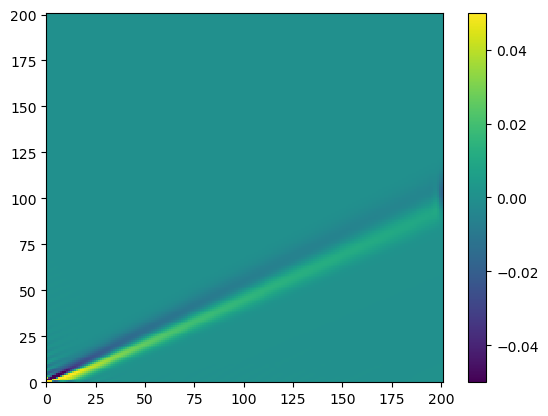

In [14]:
plt.pcolormesh(u_RBF-u,vmin = -0.05, vmax = 0.050)
plt.colorbar()

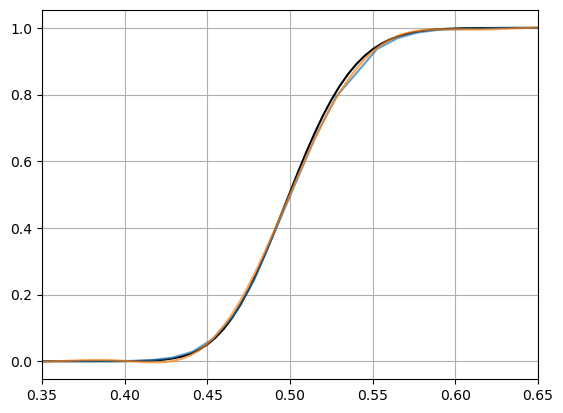

In [16]:
plt.plot(ts,u[:,-1],alpha = 1.0, c='k')
plt.plot(data_t,np.sum(u_vec*phi_data_eval,axis = 1),alpha = 0.7)
plt.plot(ts,u_pred[:,-1],alpha = 0.7)
plt.xlim(0.35,0.65)
plt.grid()

In [17]:
v0 = 0.213*805/86 * (0.8) 
D0 = 0.037*805/86**2 * (1.5) 

In [18]:
A_par_dep = A_PDE
A_par_indep = A_rest
b_par_dep = np.zeros(A_PDE.shape[:-1])
b_par_dep[0] = b_PDE
b_par_indep = b_rest
x0 = np.array([v0,D0])
grad_hess_optimize_inverse(x0, A_par_dep,A_par_indep,b_par_dep,b_par_indep,phi_data_eval,data_vals,epsilon = 1e-6*np.eye(len(Xis)))

(np.float64(4.339118642192635),
 array([ -19.83910737, -133.71715304]),
 array([[   43.51941092,    71.91214295],
        [   71.91214295, 16299.69850757]]))

In [19]:
%%time
from scipy.optimize import Bounds
maxiter = 20
params_hist_grad_hess = []
loss_hist_grad_hess = []
def fgh(x):
    xt = tuple(x)  # makes it hashable
    if xt not in _cache:
        f, g, H = grad_hess_optimize_inverse(x, A_par_dep, A_par_indep, b_par_dep, b_par_indep,phi_data_eval,data_vals,epsilon = 1e-6)  # your function
        _cache[xt] = (f, g, H)
    return _cache[xt]

def fun(x):
    params_hist_grad_hess.append(list(x))
    fun = fgh(x)[0]
    loss_hist_grad_hess.append(fun)
    print(format(fun,'.5f'), *[format(i,'.5f') for i in x])
    return fun

def grad(x):
    return fgh(x)[1]

def hess(x):
    return fgh(x)[2]
# Cache dictionary
_cache = {}
start = time.time()

bounds = Bounds([0, D/4], [np.inf, np.inf])

# Run optimizer
result_grad_hess = minimize(
    fun,
    x0,
    method='trust-constr',  # must use trust-constr to handle constraints!
    jac=grad,
    hess=hess,
    bounds = bounds,
    options={'maxiter': 30}
)

print(result_grad_hess)

time_grad_hess = time.time()-start

4.33912 1.59502 0.00604
1.45486 1.71159 0.05052
0.04639 2.03672 0.00125
0.02716 2.00941 0.00125
0.02525 2.00578 0.00151
0.01692 1.99697 0.00208
0.00439 1.98967 0.00325
0.00601 1.98612 0.00494
0.00597 1.98737 0.00494
0.00262 1.98930 0.00413
0.00262 1.98950 0.00413
0.00243 1.99005 0.00394
0.00243 1.99007 0.00394
0.00242 1.99017 0.00390
0.00242 1.99019 0.00390
0.00242 1.99020 0.00390
           message: The maximum number of function evaluations is exceeded.
           success: False
            status: 0
               fun: 0.0024219910990149716
                 x: [ 1.990e+00  3.899e-03]
               nit: 30
              nfev: 16
              njev: 15
              nhev: 15
          cg_niter: 41
      cg_stop_cond: 1
              grad: [-1.412e-06  1.130e-02]
   lagrangian_grad: [-3.695e-06  7.597e-08]
            constr: [array([ 1.990e+00,  3.899e-03])]
               jac: [<Compressed Sparse Row sparse array of dtype 'float64'
                    	with 2 stored elements and sha

In [22]:
params_PINN = np.load('PINN_problem_2_est_params.npy')
u_inv_berk = ADE_sol(data_t, [1.0], v,D)[0]
u_inv_berk = np.nan_to_num(u_inv_berk,nan = 0.0)
u_inv_RBF = ADE_sol(data_t, [1.0], *result_grad_hess.x)[0]
u_inv_RBF = np.nan_to_num(u_inv_RBF,nan = 0.0)
u_inv_PINN = ADE_sol(data_t, [1.0], *params_PINN)[0]
u_inv_PINN = np.nan_to_num(u_inv_PINN,nan = 0.0)



In [23]:
print(v*86/805,D*86**2/805)
print(format(result_grad_hess.x[0]*86/805, '.4f'),format(result_grad_hess.x[1]*86**2/805, '.4f'))
print(format(params_PINN[0]*86/805, '.4f'),format(params_PINN[1]*86**2/805, '.4f'))

0.213 0.037
0.2126 0.0358
0.2134 0.0341


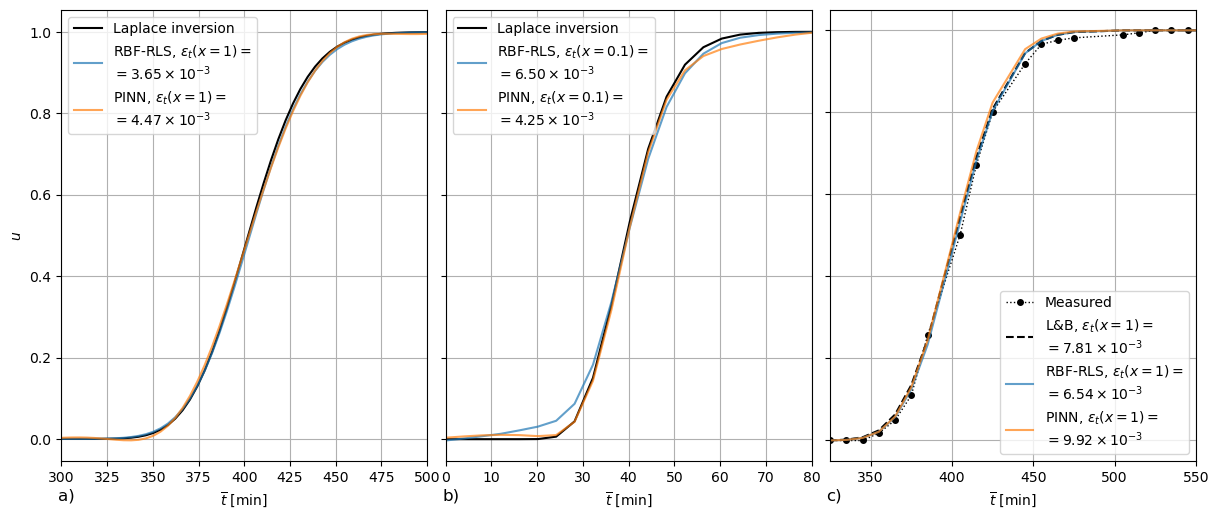

In [24]:
fig,axes  = plt.subplots(ncols = 3,figsize=(12, 5))
from math import floor
from matplotlib.lines import Line2D 


axes[0].plot(ts*berkowitz_data[-1,0],u[:,-1],alpha = 1.0, c='k', label = 'Laplace inversion')
error_RBF = np.sqrt(np.sum((u_RBF[:,-1]-u[:,-1])**2)/u.shape[1])
error_RBF_exp = int(floor(np.log10(error_RBF)))
error_RBF_mant = error_RBF/10**error_RBF_exp
axes[0].plot(ts*berkowitz_data[-1,0],u_RBF[:,-1],label = fr'RBF-RLS, $\varepsilon_t(x=1) =$'+'\n'+fr'$= {error_RBF_mant:.2f}\times 10^{{{error_RBF_exp}}}$',alpha = 0.7)
error_PINN = np.sqrt(np.sum((u_pred[:,-1]-u[:,-1])**2)/u.shape[1])
error_PINN_exp = int(floor(np.log10(error_PINN)))
error_PINN_mant = error_PINN/10**error_PINN_exp
axes[0].plot(ts*berkowitz_data[-1,0],u_pred[:,-1],label = fr'PINN, $\varepsilon_t(x=1) =$'+'\n'+fr'$= {error_PINN_mant:.2f}\times 10^{{{error_PINN_exp}}}$',alpha = 0.7)
axes[0].set_xlim(300,500)
axes[0].grid()
axes[0].legend(loc = 'upper left')
axes[0].set_ylabel(r'$u$')
axes[0].set_xlabel(r'$\overline{t}$ [min]')

axes[1].plot(ts*berkowitz_data[-1,0],u[:,len(xs)//10],alpha = 1.0, c='k', label = 'Laplace inversion')
error_RBF = np.sqrt(np.sum((u_RBF[:,len(xs)//10]-u[:,len(xs)//10])**2)/u.shape[1])
error_RBF_exp = int(floor(np.log10(error_RBF)))
error_RBF_mant = error_RBF/10**error_RBF_exp
axes[1].plot(ts*berkowitz_data[-1,0],u_RBF[:,len(xs)//10],label = fr'RBF-RLS, $\varepsilon_t(x=0.1) =$'+'\n'+fr'$= {error_RBF_mant:.2f}\times 10^{{{error_RBF_exp}}}$',alpha = 0.7)
error_PINN = np.sqrt(np.sum((u_pred[:,len(xs)//10]-u[:,len(xs)//10])**2)/u.shape[1])
error_PINN_exp = int(floor(np.log10(error_PINN)))
error_PINN_mant = error_PINN/10**error_PINN_exp
axes[1].plot(ts*berkowitz_data[-1,0],u_pred[:,len(xs)//10],label = fr'PINN, $\varepsilon_t(x=0.1) =$'+'\n'+fr'$= {error_PINN_mant:.2f}\times 10^{{{error_PINN_exp}}}$',alpha = 0.7)
axes[1].set_xlim(0,80)
axes[1].grid()
axes[1].legend(loc = 'upper left')
axes[1].set_yticklabels([])
axes[1].set_xlabel(r'$\overline{t}$ [min]')

axes[2].plot(berkowitz_data[:,0],data_vals, c='k', marker = 'o', markersize = 4, linestyle = 'dotted',linewidth = 1.0, label = 'Measured')
error_berk = np.sqrt(np.sum((u_inv_berk-data_vals)**2)/len(data_vals))
error_berk_exp = int(floor(np.log10(error_berk)))
error_berk_mant = error_berk/10**error_berk_exp
axes[2].plot(berkowitz_data[:,0],u_inv_berk,label = fr'L&B, $\varepsilon_t(x=1) =$'+'\n'+fr'$= {error_berk_mant:.2f}\times 10^{{{error_berk_exp}}}$', c = 'k',linestyle = 'dashed')
error_RBF = np.sqrt(np.sum((u_inv_RBF-data_vals)**2)/len(data_vals))
error_RBF_exp = int(floor(np.log10(error_RBF)))
error_RBF_mant = error_RBF/10**(int(np.log10(error_RBF))-1)
axes[2].plot(berkowitz_data[:,0],u_inv_RBF,label = fr'RBF-RLS, $\varepsilon_t(x=1) =$'+'\n'+fr'$= {error_RBF_mant:.2f}\times 10^{{{error_RBF_exp}}}$', alpha = 0.7)
error_PINN = np.sqrt(np.sum((u_inv_PINN-data_vals)**2)/len(data_vals))
error_PINN_exp = int(floor(np.log10(error_PINN)))
error_PINN_mant = error_PINN/10**error_PINN_exp
axes[2].plot(berkowitz_data[:,0],u_inv_PINN,label = fr'PINN, $\varepsilon_t(x=1) =$'+'\n'+fr'$= {error_PINN_mant:.2f}\times 10^{{{error_PINN_exp}}}$', alpha = 0.7)
axes[2].set_xlim(325,550)
axes[2].grid()
axes[2].set_yticklabels([])
axes[2].legend(loc = 'lower right')
axes[2].set_xlabel(r'$\overline{t}$ [min]')

labels = ['a)', 'b)', 'c)']

for ax, label in zip(axes.flat, labels):
    ax.text(
        -0.01, -0.06, label,
        transform=ax.transAxes,
        fontsize=12,
        va='top', ha='left'
    )



plt.tight_layout(pad=.03)
plt.show()

In [25]:
np.sqrt(np.sum((u_RBF-u)**2)/u.size),np.sqrt(np.sum((u_pred-u)**2)/u.size)

(np.float64(0.004736876362154725), np.float64(0.004940772074168304))